# 01 — Quantum computing basics with Qiskit

This notebook introduces quantum computing and the core of **[Qiskit](https://github.com/Qiskit/qiskit)** 2.x. Qiskit is IBM's open-source software development kit (SDK) for building, simulating and compiling quantum circuits. Each physics concept comes with the matching code.

**Based on**
- Qiskit guides: [*Construct circuits*](https://quantum.cloud.ibm.com/docs/en/guides/construct-circuits), [*Visualize circuits*](https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits), [*Bit ordering in the Qiskit SDK*](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering), [*Introduction to primitives*](https://quantum.cloud.ibm.com/docs/en/guides/primitives), [*Primitive inputs and outputs*](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output), [*Introduction to transpilation*](https://quantum.cloud.ibm.com/docs/en/guides/transpile), [*Transpile with pass managers*](https://quantum.cloud.ibm.com/docs/en/guides/transpile-with-pass-managers), [*Classical feedforward and control flow*](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow).
- IBM Quantum Learning, J. Watrous, [*Basics of quantum information*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information). Sections 1–7 and the teleportation section follow this course.
- IBM Quantum Learning, J. Watrous, [*Fundamentals of quantum algorithms*](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms). The Deutsch–Jozsa, Bernstein–Vazirani, Grover and QFT sections follow this course.
- Qiskit tutorial [*Grover's algorithm*](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm) (Section 15).
- The [Qiskit SDK API reference](https://quantum.cloud.ibm.com/docs/en/api/qiskit). Each section links the API page of the classes it uses.

The examples and code are adapted from these sources.

**Contents**

1. Classical bits and qubits, Dirac notation, state vectors
2. The Bloch sphere
3. Measurement and the Born rule
4. Single-qubit gates (X, Y, Z, H, S, T, rotations) and their matrices
5. Superposition and interference
6. Multi-qubit states and tensor products
7. CNOT, entanglement and Bell states
8. Building and drawing circuits
9. Primitives: `StatevectorSampler` and `StatevectorEstimator` (V2 PUB format), observables with `SparsePauliOp`
10. Parameterized circuits
11. Transpilation to a target backend (`GenericBackendV2`, `generate_preset_pass_manager`)
12. Noise
13. Quantum teleportation
14. Deutsch–Jozsa and Bernstein–Vazirani
15. Grover search
16. The quantum Fourier transform (QFT)

**Installation**
```bash
pip install "qiskit[visualization]"
```
Section 13 also uses Qiskit Aer (`pip install qiskit-aer`).

All examples use at most 7 qubits and run on a CPU.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import qiskit

from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector, Operator, SparsePauliOp, partial_trace, entropy
from qiskit.visualization import plot_bloch_multivector, plot_histogram, array_to_latex
from qiskit.primitives import StatevectorSampler, StatevectorEstimator

print("Qiskit version:", qiskit.__version__)

def fmt(d, nd=3):
    # Format a dict of probabilities or amplitudes with plain Python numbers, rounded to nd digits
    return {str(k): (round(complex(v).real, nd) if abs(complex(v).imag) < 1e-12 else np.round(complex(v), nd)) for k, v in d.items()}

Qiskit version: 2.5.2


## 1. Classical bits and qubits

A **classical bit** is always in one of two states: `0` or `1`. A register of $n$ bits holds one of $2^n$ values at a time.

A **qubit** is a two-level quantum system. Examples are the spin of an electron or two energy levels of a superconducting circuit. The state of a qubit is a *vector* in a two-dimensional complex vector space. We write the two basis states in **Dirac (bra–ket) notation**:

$$
|0\rangle = \begin{pmatrix}1\\0\end{pmatrix}, \qquad |1\rangle = \begin{pmatrix}0\\1\end{pmatrix}.
$$

A general qubit state is a **superposition** (a linear combination) of the basis states:

$$
|\psi\rangle = \alpha|0\rangle + \beta|1\rangle = \begin{pmatrix}\alpha\\ \beta\end{pmatrix}, \qquad \alpha,\beta\in\mathbb{C},\quad |\alpha|^2+|\beta|^2 = 1.
$$

The complex numbers $\alpha$ and $\beta$ are called **amplitudes**.

Terms:

* A **ket** $|\psi\rangle$ is a column vector. The **bra** $\langle\psi| = (|\psi\rangle)^\dagger$ is its conjugate transpose (a row vector).
* The **inner product** $\langle\phi|\psi\rangle$ is a complex number. $|\langle\phi|\psi\rangle|^2$ measures the overlap of the two states.
* The **normalization** condition is $\langle\psi|\psi\rangle = 1$.
* A **global phase** cannot be observed: $|\psi\rangle$ and $e^{i\gamma}|\psi\rangle$ describe the same physical state.

Two other common states are

$$
|+\rangle = \tfrac{1}{\sqrt2}(|0\rangle + |1\rangle), \qquad |-\rangle = \tfrac{1}{\sqrt2}(|0\rangle - |1\rangle).
$$

In Qiskit, the class [`qiskit.quantum_info.Statevector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector) represents these vectors. The theory follows the Watrous lesson [*Single systems*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/introduction).

In [2]:
ket0 = Statevector.from_label("0")
ket1 = Statevector.from_label("1")
plus = Statevector.from_label("+")
minus = Statevector.from_label("-")

print("|0> =", ket0.data)
print("|+> =", plus.data)

# A general state alpha|0> + beta|1>
alpha, beta = 1/np.sqrt(3), np.sqrt(2/3) * np.exp(1j*np.pi/4)
psi = Statevector([alpha, beta])
print("Is psi a valid (normalized) state?", psi.is_valid())

# Inner products <phi|psi>
print("<0|+>  =", ket0.inner(plus))
print("<+|->  =", plus.inner(minus))
psi.draw("latex")

|0> = [1.+0.j 0.+0.j]
|+> = [0.70710678+0.j 0.70710678+0.j]
Is psi a valid (normalized) state? True
<0|+>  = (0.7071067811865475+0j)
<+|->  = (-2.2371143170757382e-17+0j)


<IPython.core.display.Latex object>

## 2. The Bloch sphere

Normalization fixes the length of the state vector, and the global phase has no physical meaning. Therefore two real angles describe any single-qubit pure state:

$$
|\psi\rangle = \cos\tfrac{\theta}{2}\,|0\rangle + e^{i\varphi}\sin\tfrac{\theta}{2}\,|1\rangle, \qquad 0\le\theta\le\pi,\; 0\le\varphi<2\pi.
$$

$\theta$ and $\varphi$ are the polar and azimuthal angles of a point on the unit sphere. This sphere is the **Bloch sphere**.

| Position on the sphere | State |
|---|---|
| North pole ($+z$) | $|0\rangle$ |
| South pole ($-z$) | $|1\rangle$ |
| $\pm x$ on the equator | $|\pm\rangle$ |
| $\pm y$ on the equator | $|{\pm i}\rangle = (|0\rangle \pm i|1\rangle)/\sqrt2$ |

The Cartesian coordinates of the **Bloch vector** are the expectation values of the Pauli operators: $\vec r = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle)$.

[`plot_bloch_multivector`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_bloch_multivector) draws one Bloch sphere per qubit.

Bloch vector (<X>,<Y>,<Z>) = [0.6124 0.6124 0.5   ]
Expected:  [0.6124 0.6124 0.5   ]


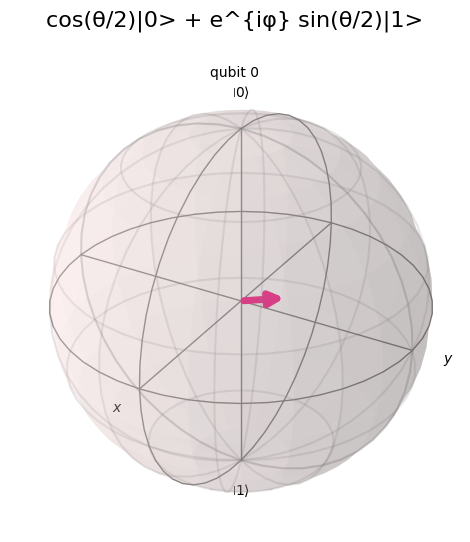

In [3]:
theta, phi = np.pi/3, np.pi/4
psi = Statevector([np.cos(theta/2), np.exp(1j*phi)*np.sin(theta/2)])

# Bloch vector from Pauli expectation values
r = [psi.expectation_value(SparsePauliOp(p)).real for p in "XYZ"]
print("Bloch vector (<X>,<Y>,<Z>) =", np.round(r, 4))
print("Expected: ", np.round([np.sin(theta)*np.cos(phi), np.sin(theta)*np.sin(phi), np.cos(theta)], 4))

plot_bloch_multivector(psi, title="cos(θ/2)|0> + e^{iφ} sin(θ/2)|1>")

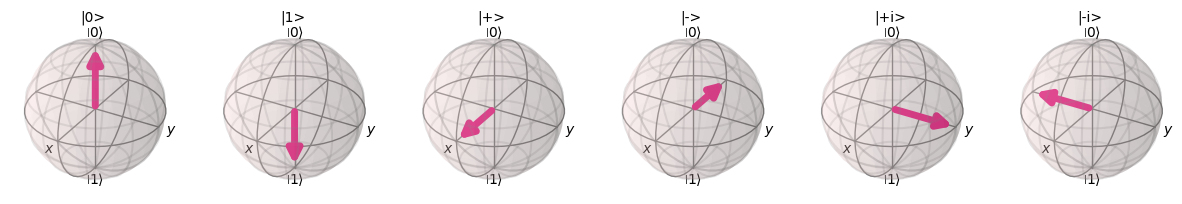

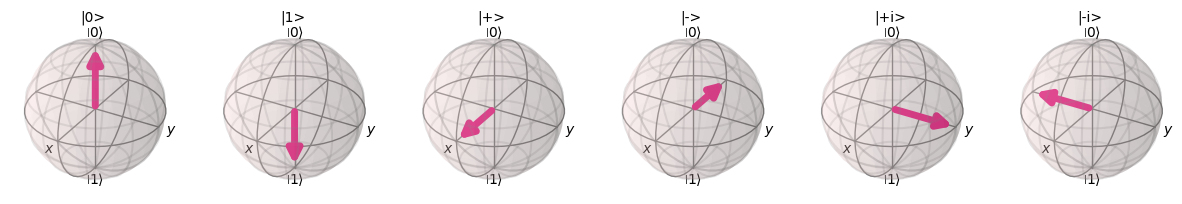

In [4]:
# A few landmark states side by side, drawn with plot_bloch_vector from their (<X>,<Y>,<Z>)
# Statevector labels: 'r' = |+i>, 'l' = |-i>
from qiskit.visualization import plot_bloch_vector
fig, axes = plt.subplots(1, 6, figsize=(15, 3), subplot_kw={"projection": "3d"})
names = {"0": "|0>", "1": "|1>", "+": "|+>", "-": "|->", "r": "|+i>", "l": "|-i>"}
for ax, label in zip(axes, names):
    sv = Statevector.from_label(label)
    vec = [sv.expectation_value(SparsePauliOp(p)).real for p in "XYZ"]
    plot_bloch_vector(vec, ax=ax, title=names[label], font_size=10)
fig

## 3. Measurement and the Born rule

Amplitudes cannot be observed directly. A measurement of a qubit in the computational ($Z$) basis gives a classical bit. The **Born rule** gives the probabilities:

$$
P(0) = |\langle 0|\psi\rangle|^2 = |\alpha|^2, \qquad P(1) = |\langle 1|\psi\rangle|^2 = |\beta|^2 .
$$

* After the measurement, the state **collapses** to the observed basis state. A second measurement gives the same result.
* Measurement is irreversible and random. To estimate the probabilities, we prepare and measure the state many times. Each repetition is a **shot**.
* For an $n$-qubit state $|\psi\rangle=\sum_x c_x |x\rangle$, the bitstring $x$ occurs with probability $|c_x|^2$.

In the example below, $P(1) = 0.8$. With 1000 shots the sampled count of `1` is 782.

In [5]:
psi = Statevector([np.sqrt(0.2), np.sqrt(0.8)])
print("Exact probabilities:", fmt(psi.probabilities_dict()))

# Simulate finite sampling ("shots")
psi.seed(42)
counts = psi.sample_counts(shots=1000)
print("Sampled counts (1000 shots):", {str(k): int(v) for k, v in counts.items()})

# Collapse: measure once and inspect the post-measurement state
outcome, post_state = psi.measure()
print("Outcome:", outcome, "-> post-measurement state:", post_state.data)

Exact probabilities: {'0': 0.2, '1': 0.8}
Sampled counts (1000 shots): {'0': 218, '1': 782}
Outcome: 0 -> post-measurement state: [1.+0.j 0.+0.j]


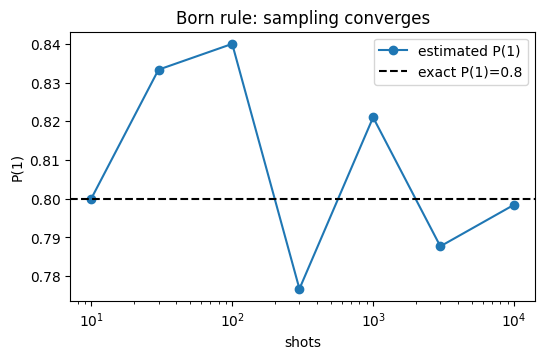

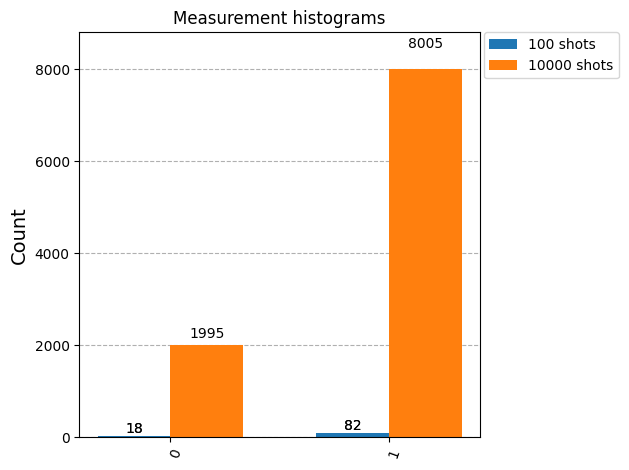

In [6]:
# Convergence: the error of the estimate of P(1) decreases like 1/sqrt(shots)
shots_list = [10, 30, 100, 300, 1000, 3000, 10000]
psi.seed(1)
est = [psi.sample_counts(s).get("1", 0)/s for s in shots_list]
plt.figure(figsize=(6, 3.5))
plt.semilogx(shots_list, est, "o-", label="estimated P(1)")
plt.axhline(0.8, color="k", ls="--", label="exact P(1)=0.8")
plt.xlabel("shots"); plt.ylabel("P(1)"); plt.legend(); plt.title("Born rule: sampling converges")
plt.show()

plot_histogram([psi.sample_counts(100), psi.sample_counts(10000)],
               legend=["100 shots", "10000 shots"], title="Measurement histograms")

## 4. Single-qubit gates

A quantum gate is a **unitary** matrix ($U^\dagger U = I$). Unitary matrices preserve normalization and are reversible. On the Bloch sphere, every single-qubit gate is a **rotation**.

| Gate | Matrix | Action |
|---|---|---|
| $X$ (NOT) | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ | $\pi$ rotation about $x$; $\|0\rangle\leftrightarrow\|1\rangle$ |
| $Y$ | $\begin{pmatrix}0&-i\\i&0\end{pmatrix}$ | $\pi$ rotation about $y$ |
| $Z$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ | $\pi$ rotation about $z$; phase flip $\|1\rangle\to-\|1\rangle$ |
| $H$ (Hadamard) | $\tfrac{1}{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ | $\|0\rangle\to\|+\rangle$, $\|1\rangle\to\|-\rangle$ |
| $S=\sqrt Z$ | $\begin{pmatrix}1&0\\0&i\end{pmatrix}$ | $\pi/2$ about $z$ |
| $T=\sqrt S$ | $\begin{pmatrix}1&0\\0&e^{i\pi/4}\end{pmatrix}$ | $\pi/4$ about $z$ |
| $R_x(\theta)$ | $e^{-i\theta X/2}=\begin{pmatrix}\cos\frac\theta2&-i\sin\frac\theta2\\-i\sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | angle $\theta$ about $x$ |
| $R_y(\theta)$ | $e^{-i\theta Y/2}=\begin{pmatrix}\cos\frac\theta2&-\sin\frac\theta2\\\sin\frac\theta2&\cos\frac\theta2\end{pmatrix}$ | angle $\theta$ about $y$ |
| $R_z(\theta)$ | $e^{-i\theta Z/2}=\begin{pmatrix}e^{-i\theta/2}&0\\0&e^{i\theta/2}\end{pmatrix}$ | angle $\theta$ about $z$ |

In Qiskit, we apply gates to a [`QuantumCircuit`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit) (guide: [*Construct circuits*](https://quantum.cloud.ibm.com/docs/en/guides/construct-circuits)). [`qiskit.quantum_info.Operator`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Operator) converts a gate, or a circuit without measurements, into its unitary matrix. Gates and circuits are introduced in the Watrous lesson [*Quantum circuits*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/quantum-circuits/introduction).

In [7]:
gates = {}
for name in ["x", "y", "z", "h", "s", "t"]:
    qc = QuantumCircuit(1)
    getattr(qc, name)(0)
    gates[name.upper()] = Operator(qc)

for name, op in gates.items():
    print(f"{name} =\n{np.round(op.data, 3)}\n")

X =
[[0.+0.j 1.+0.j]
 [1.+0.j 0.+0.j]]

Y =
[[0.+0.j 0.-1.j]
 [0.+1.j 0.+0.j]]

Z =
[[ 1.+0.j  0.+0.j]
 [ 0.+0.j -1.+0.j]]

H =
[[ 0.707+0.j  0.707+0.j]
 [ 0.707+0.j -0.707+0.j]]

S =
[[1.+0.j 0.+0.j]
 [0.+0.j 0.+1.j]]

T =
[[1.   +0.j    0.   +0.j   ]
 [0.   +0.j    0.707+0.707j]]



In [8]:
# Render a matrix as LaTeX
array_to_latex(gates["H"].data, prefix=r"H = ")

<IPython.core.display.Latex object>

In [9]:
# Rotation gates: compare Qiskit's matrix with the analytic formula
theta = 0.7
qc = QuantumCircuit(1); qc.ry(theta, 0)
Ry_qiskit = Operator(qc).data
Ry_formula = np.array([[np.cos(theta/2), -np.sin(theta/2)], [np.sin(theta/2), np.cos(theta/2)]])
print("Ry matches formula:", np.allclose(Ry_qiskit, Ry_formula))

# Algebraic identities (equal up to global phase -> use .equiv)
X, Y, Z, H, S, T = (gates[k] for k in "XYZHST")
print("H X H == Z      :", (H @ X @ H).equiv(Z))
print("S S == Z        :", (S @ S).equiv(Z))
print("T T == S        :", (T @ T).equiv(S))
print("X is unitary    :", X.is_unitary())
qc_rx = QuantumCircuit(1); qc_rx.rx(np.pi, 0)
print("Rx(pi) == X (up to global phase):", Operator(qc_rx).equiv(X), "| exactly equal:", Operator(qc_rx) == X)

Ry matches formula: True
H X H == Z      : True
S S == Z        : True
T T == S        : True
X is unitary    : True
Rx(pi) == X (up to global phase): True | exactly equal: False


The last line shows that $R_x(\pi) = -iX$. The two operators differ only by the **global phase** $-i$, so they are physically the same. `Operator.equiv` ignores the global phase. The `==` operator does not.

Next, we show gates as rotations. We start from $|0\rangle$ and apply $H$, then $S$, then $T$.

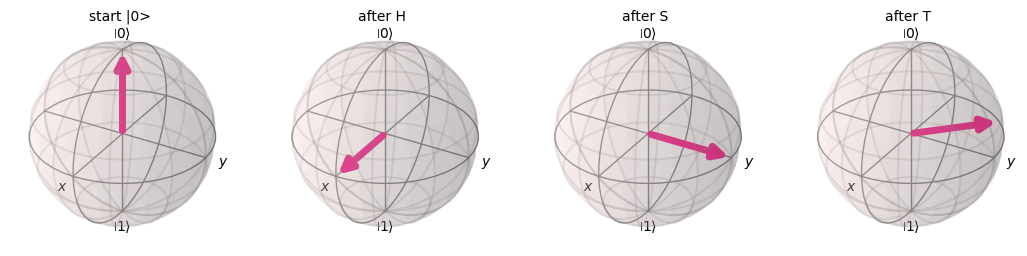

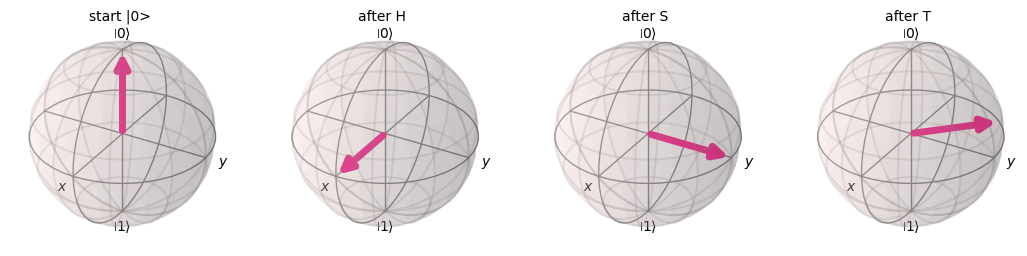

In [10]:
qc = QuantumCircuit(1)
states = [("start |0>", Statevector(qc))]
for g in ["h", "s", "t"]:
    getattr(qc, g)(0)
    states.append((f"after {g.upper()}", Statevector(qc)))

fig, axes = plt.subplots(1, 4, figsize=(13, 3.3), subplot_kw={"projection": "3d"})
for ax, (title, sv) in zip(axes, states):
    vec = [sv.expectation_value(SparsePauliOp(p)).real for p in "XYZ"]
    plot_bloch_vector(vec, ax=ax, title=title, font_size=10)
fig

## 5. Superposition and interference

The Hadamard gate creates an equal superposition from a basis state:
$$H|0\rangle = |+\rangle = \tfrac{1}{\sqrt2}(|0\rangle+|1\rangle).$$
A measurement of $|+\rangle$ gives 0 or 1, each with probability ½. A fair coin gives the same statistics. However, a superposition is **not** classical randomness, because amplitudes can **interfere**. If we apply $H$ again:

$$
H|+\rangle = \tfrac{1}{\sqrt2}\big(H|0\rangle + H|1\rangle\big) = \tfrac12\big(|0\rangle+|1\rangle+|0\rangle-|1\rangle\big) = |0\rangle .
$$

* The two $|1\rangle$ amplitudes cancel. This is **destructive interference**.
* The two $|0\rangle$ amplitudes add. This is **constructive interference**.

A classical coin flipped twice is still random. In contrast, $HH = I$ is deterministic. Quantum algorithms use interference to increase the probability of correct answers.

In [11]:
one_h = QuantumCircuit(1); one_h.h(0)
two_h = QuantumCircuit(1); two_h.h(0); two_h.h(0)
# A Z between the two H gates changes the relative phase, so the other outcome interferes constructively
hzh = QuantumCircuit(1); hzh.h(0); hzh.z(0); hzh.h(0)

for name, c in [("H", one_h), ("H H", two_h), ("H Z H", hzh)]:
    print(f"{name:6s} -> probabilities {fmt(Statevector(c).probabilities_dict())}")

H      -> probabilities {'0': 0.5, '1': 0.5}
H H    -> probabilities {'0': 1.0}
H Z H  -> probabilities {'1': 1.0}


## 6. Multi-qubit states and tensor products

The state space of $n$ qubits is the **tensor product** of the single-qubit spaces. Its dimension is $2^n$. For two qubits:

$$
|a\rangle\otimes|b\rangle = \begin{pmatrix}a_0\\a_1\end{pmatrix}\otimes\begin{pmatrix}b_0\\b_1\end{pmatrix} = \begin{pmatrix}a_0b_0\\a_0b_1\\a_1b_0\\a_1b_1\end{pmatrix},
$$

with basis $|00\rangle,|01\rangle,|10\rangle,|11\rangle$. A general 2-qubit state is $\sum_{x\in\{0,1\}^2} c_x |x\rangle$ with 4 complex amplitudes. A state of $n$ qubits needs $2^n$ amplitudes. For this reason, the cost of classical simulation grows exponentially with $n$ (see the Watrous lesson [*Multiple systems*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/introduction)).

> **Bit ordering in Qiskit (little-endian).** **Qubit 0 is the rightmost** character of a bitstring: $|q_{n-1}\cdots q_1 q_0\rangle$ (guide: [*Bit ordering in the Qiskit SDK*](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering)). In the same way, `Statevector.tensor(other)` returns `self ⊗ other`, and `other` becomes the *lower* qubit(s). Use this rule to read histograms.

In [12]:
a = Statevector.from_label("0")
b = Statevector.from_label("+")
ab = a.tensor(b)           # |0> ⊗ |+>  : |+> sits on qubit 0 (rightmost)
print("a ⊗ b amplitudes:", np.round(ab.data, 3))
print("probabilities   :", fmt(ab.probabilities_dict()))

# Same state built from a circuit: H on qubit 0 only
qc = QuantumCircuit(2); qc.h(0)
print("Circuit state equals |0>⊗|+> :", Statevector(qc).equiv(ab))

# Operators also combine with tensor products: (X ⊗ I) flips qubit 1
XI = Operator.from_label("XI")
print("(X⊗I)|00> =", fmt(Statevector.from_label("00").evolve(XI).probabilities_dict()))

a ⊗ b amplitudes: [0.707+0.j 0.707+0.j 0.   +0.j 0.   +0.j]
probabilities   : {'00': 0.5, '01': 0.5}
Circuit state equals |0>⊗|+> : True
(X⊗I)|00> = {'10': 1.0}


<IPython.core.display.Latex object>

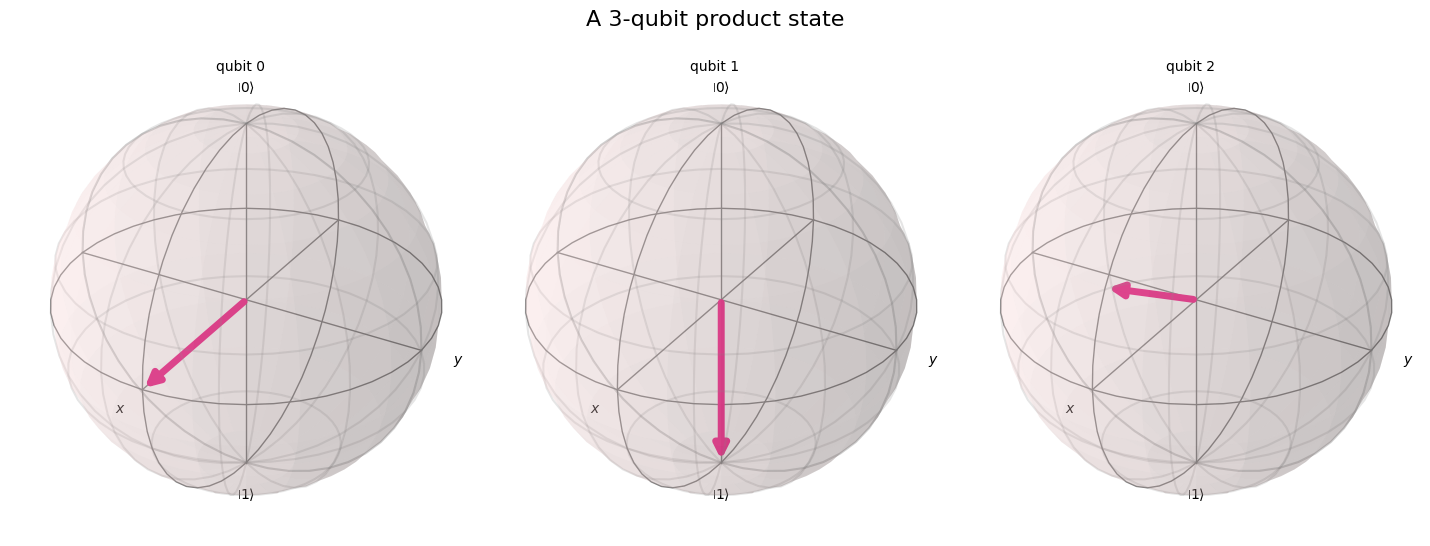

In [13]:
# Single-qubit gates on several qubits create product states
qc = QuantumCircuit(3)
qc.h(0); qc.x(1); qc.ry(np.pi/3, 2)
sv = Statevector(qc)
display(sv.draw("latex"))
plot_bloch_multivector(sv, title="A 3-qubit product state")

## 7. CNOT and entanglement: Bell states

The **controlled-NOT** gate (CNOT, `cx`) flips the target qubit if and only if the control qubit is $|1\rangle$: $\text{CNOT}|c,t\rangle = |c,\,t\oplus c\rangle$. Here $\oplus$ is addition modulo 2. With control on qubit 0 and target on qubit 1 (Qiskit ordering $|q_1q_0\rangle$):

$$
\text{CNOT}_{0\to1} = \begin{pmatrix}1&0&0&0\\0&0&0&1\\0&0&1&0\\0&1&0&0\end{pmatrix}.
$$

We start from $|00\rangle$ and apply a Hadamard and then a CNOT. The result is the **Bell state**

$$
|\Phi^+\rangle = \text{CNOT}\,(H\otimes I)|00\rangle = \tfrac{1}{\sqrt2}\big(|00\rangle + |11\rangle\big).
$$

This state is **entangled**: it cannot be written as a product $|a\rangle\otimes|b\rangle$. A measurement of either qubit gives a random result. However, the two results are always **perfectly correlated**. The four Bell states form an orthonormal basis:

$$
|\Phi^\pm\rangle = \tfrac{1}{\sqrt2}(|00\rangle\pm|11\rangle), \qquad |\Psi^\pm\rangle = \tfrac{1}{\sqrt2}(|01\rangle\pm|10\rangle).
$$

In [14]:
cx = QuantumCircuit(2); cx.cx(0, 1)
array_to_latex(Operator(cx).data, prefix=r"\mathrm{CNOT}_{0\to 1} = ")

<IPython.core.display.Latex object>

phi+ : {'00': 0.707, '11': 0.707}
phi- : {'00': 0.707, '11': -0.707}
psi+ : {'01': 0.707, '10': 0.707}
psi- : {'01': -0.707, '10': 0.707}


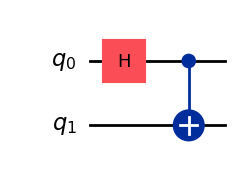

In [15]:
def bell_circuit(kind="phi+"):
    qc = QuantumCircuit(2, name=kind)
    if kind in ("psi+", "psi-"):
        qc.x(1)
    if kind in ("phi-", "psi-"):
        qc.x(0)
    qc.h(0)
    qc.cx(0, 1)
    return qc

for kind in ["phi+", "phi-", "psi+", "psi-"]:
    sv = Statevector(bell_circuit(kind))
    print(f"{kind:5s}:", fmt(sv.to_dict()))

bell = bell_circuit("phi+")
bell.draw("mpl")

**Test for entanglement.** For a pure two-qubit state, compute the **reduced density matrix** of one qubit, $\rho_A = \mathrm{Tr}_B\,|\psi\rangle\langle\psi|$. A density matrix describes the state of a subsystem, including statistical mixtures.

* For a product state, $\rho_A$ is pure. Its entropy is 0.
* For a maximally entangled state, $\rho_A = I/2$ (maximally mixed). The entanglement entropy is 1 bit.

The Bloch vectors of the single qubits also have zero length. Neither qubit alone has a definite state.

product |0>|+> : entanglement entropy S(ρ_A) = 0.000 bits
Bell |Φ+>      : entanglement entropy S(ρ_A) = 1.000 bits

ρ_A for the Bell state:
 [[0.5+0.j 0. +0.j]
 [0. +0.j 0.5+0.j]]


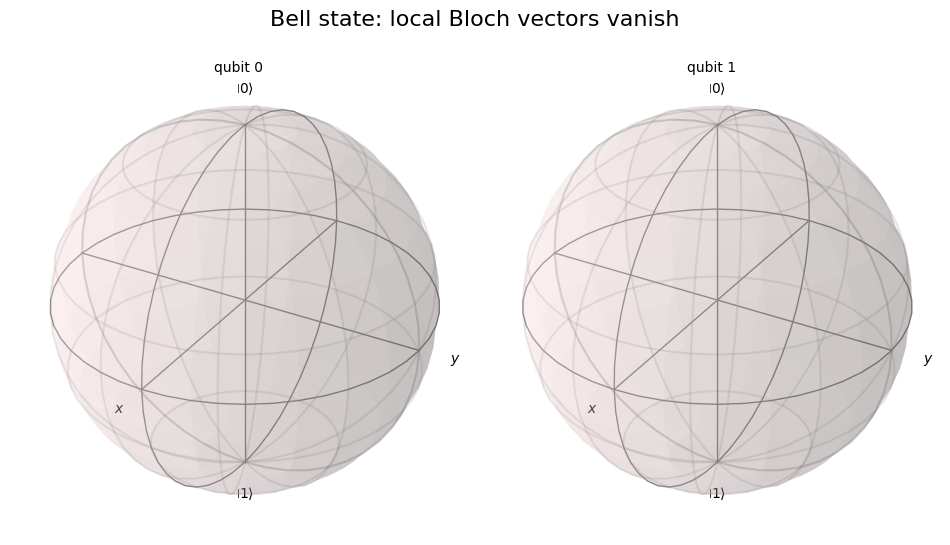

In [16]:
sv_bell = Statevector(bell)
sv_prod = Statevector.from_label("0+")

for name, sv in [("product |0>|+>", sv_prod), ("Bell |Φ+>", sv_bell)]:
    rho_A = partial_trace(sv, [1])       # trace out qubit 1
    print(f"{name:15s}: entanglement entropy S(ρ_A) = {entropy(rho_A, base=2):.3f} bits")

print("\nρ_A for the Bell state:\n", np.round(partial_trace(sv_bell, [1]).data, 3))
plot_bloch_multivector(sv_bell, title="Bell state: local Bloch vectors vanish")

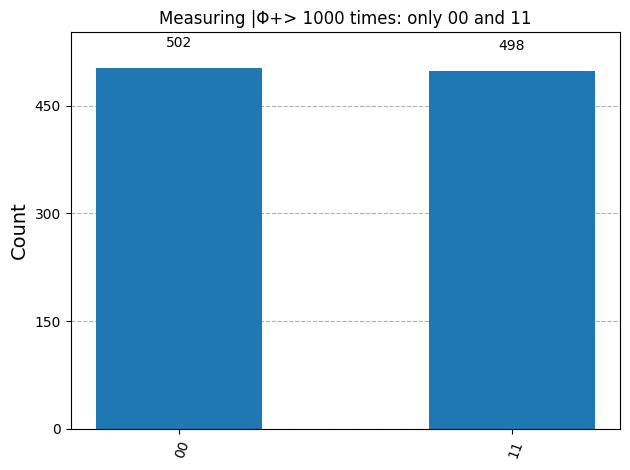

In [17]:
# Perfect correlation in measurement samples
sv_bell.seed(7)
plot_histogram(sv_bell.sample_counts(1000), title="Measuring |Φ+> 1000 times: only 00 and 11")

**GHZ state.** A chain of CNOTs entangles more qubits: $|\mathrm{GHZ}_n\rangle = (|0\cdots0\rangle + |1\cdots1\rangle)/\sqrt2$.

{'0000': 0.5, '1111': 0.5}


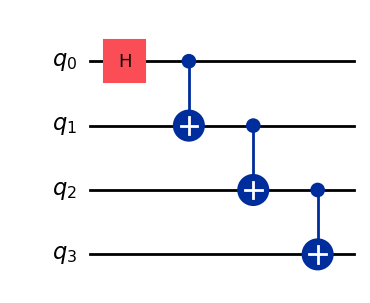

In [18]:
n = 4
ghz = QuantumCircuit(n)
ghz.h(0)
for i in range(n - 1):
    ghz.cx(i, i + 1)
print(fmt(Statevector(ghz).probabilities_dict()))
ghz.draw("mpl")

## 8. Building and drawing circuits

A [`QuantumCircuit`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit) holds quantum and classical **registers** and a list of instructions (guide: [*Construct circuits*](https://quantum.cloud.ibm.com/docs/en/guides/construct-circuits)). Common methods:

| Method | Purpose |
|---|---|
| `qc.measure(qubits, clbits)`, `qc.measure_all()` | Add measurements. `measure_all` creates a classical register named `meas`. |
| `qc.barrier()` | Visual separator. The transpiler does not move gates across it. |
| `qc.draw("mpl")`, `qc.draw("text")`, `qc.draw("latex")` | Draw with matplotlib, as text, or with LaTeX (needs a LaTeX installation). See the guide [*Visualize circuits*](https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits). |
| `qc.depth()`, `qc.size()`, `qc.count_ops()` | Resource counts. |
| `qc.compose(other)`, `qc.inverse()` | Combine circuits; `inverse` returns $U^\dagger$. |

        ┌───┐         ░          ░ ┌─┐      
q_0: ───┤ H ├─────■───░──■───■───░─┤M├──────
        └───┘   ┌─┴─┐ ░  │   │   ░ └╥┘┌─┐   
q_1: ───────────┤ X ├─░──X───■───░──╫─┤M├───
     ┌─────────┐└───┘ ░  │ ┌─┴─┐ ░  ║ └╥┘┌─┐
q_2: ┤ Rz(π/4) ├──────░──X─┤ X ├─░──╫──╫─┤M├
     └─────────┘      ░    └───┘ ░  ║  ║ └╥┘
c: 3/═══════════════════════════════╩══╩══╩═
                                    0  1  2 
depth: 5 | size: 8 | ops: {'measure': 3, 'barrier': 2, 'h': 1, 'cx': 1, 'rz': 1, 'cswap': 1, 'ccx': 1}


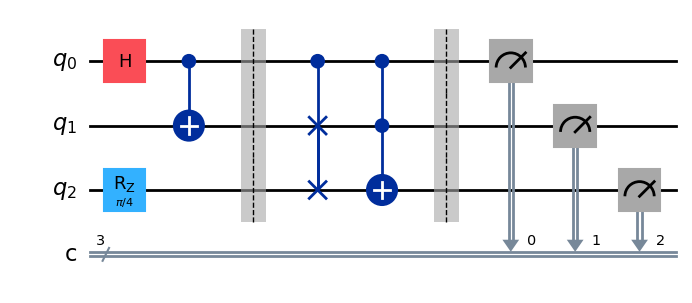

In [19]:
qr = QuantumRegister(3, "q")
cr = ClassicalRegister(3, "c")
qc = QuantumCircuit(qr, cr, name="demo")
qc.h(qr[0])
qc.cx(qr[0], qr[1])
qc.rz(np.pi/4, qr[2])
qc.barrier()
qc.cswap(qr[0], qr[1], qr[2])
qc.ccx(qr[0], qr[1], qr[2])         # Toffoli
qc.barrier()
qc.measure(qr, cr)

print(qc.draw("text"))
print("depth:", qc.depth(), "| size:", qc.size(), "| ops:", dict(qc.count_ops()))
qc.draw("mpl")

U · U† == I : True


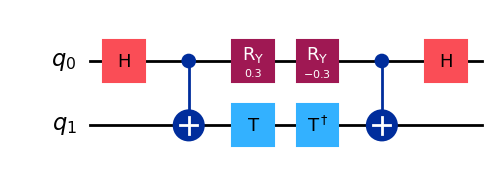

In [20]:
# Composition and inversion: U followed by U^dagger is the identity
u = QuantumCircuit(2)
u.h(0); u.cx(0, 1); u.t(1); u.ry(0.3, 0)
roundtrip = u.compose(u.inverse())
print("U · U† == I :", Operator(roundtrip).equiv(Operator(QuantumCircuit(2))))
roundtrip.draw("mpl", fold=-1)

## 9. Primitives: Sampler and Estimator (V2)

Quantum programs run through **primitives** (guide: [*Introduction to primitives*](https://quantum.cloud.ibm.com/docs/en/guides/primitives)). Primitives have the same interface on local simulators and on IBM Quantum hardware (`qiskit_ibm_runtime.SamplerV2` and `EstimatorV2`).

* **Sampler**: runs circuits *with measurements* and returns the measured bitstrings (shots).
* **Estimator**: computes expectation values $\langle\psi|O|\psi\rangle$ of observables $O$ for circuits *without measurements*.

[`qiskit.primitives.StatevectorSampler`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler) and [`StatevectorEstimator`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator) are exact local reference implementations.

**PUBs (primitive unified blocs).** The input is a list of PUBs (guide: [*Primitive inputs and outputs*](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output)):

* Sampler PUB: `(circuit,)`, `(circuit, parameter_values)` or `(circuit, parameter_values, shots)`
* Estimator PUB: `(circuit, observables)`, `(circuit, observables, parameter_values)` or `(circuit, observables, parameter_values, precision)`

`observables` and `parameter_values` are **broadcast** against each other with NumPy rules. Therefore one PUB can describe a full parameter sweep. `job.result()` returns a `PrimitiveResult` with one `PubResult` per PUB.

Bell : {'11': 499, '00': 501}  shots = 1000
GHZ  : {'1111': 978, '0000': 1022}  shots = 2000
First 5 Bell bitstrings: ['11', '00', '00', '00', '00']


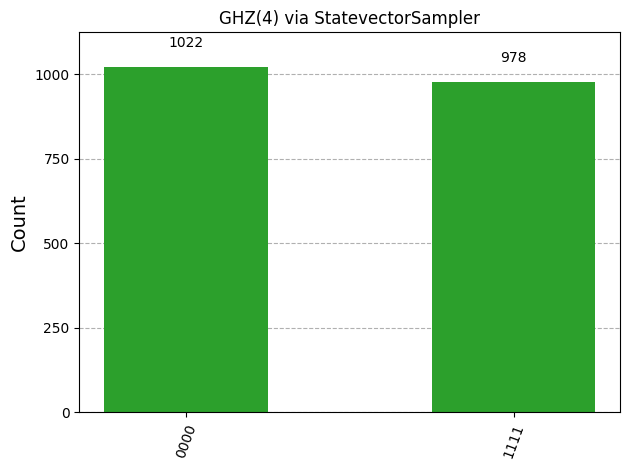

In [21]:
sampler = StatevectorSampler(seed=123)

bell_meas = bell_circuit("phi+")
bell_meas.measure_all()
ghz_meas = ghz.copy(); ghz_meas.measure_all()

job = sampler.run([(bell_meas,), (ghz_meas, None, 2000)], shots=1000)   # 2nd PUB overrides shots
result = job.result()

bell_counts = result[0].data.meas.get_counts()     # data is accessed by classical register name
ghz_counts = result[1].data.meas.get_counts()
print("Bell :", bell_counts, " shots =", result[0].data.meas.num_shots)
print("GHZ  :", ghz_counts, " shots =", result[1].data.meas.num_shots)
print("First 5 Bell bitstrings:", result[0].data.meas.get_bitstrings()[:5])

plot_histogram(ghz_counts, title="GHZ(4) via StatevectorSampler", color="tab:green")

### Observables with `SparsePauliOp`

A physical observable is a Hermitian operator. Every $n$-qubit observable is a real linear combination of **Pauli strings** $P = P_{n-1}\otimes\cdots\otimes P_0$, with $P_i\in\{I,X,Y,Z\}$. [`SparsePauliOp`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.SparsePauliOp) stores observables in this form. The **rightmost** character acts on qubit 0 ([bit ordering](https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering)).

For the Bell state $|\Phi^+\rangle$, $\langle ZZ\rangle = \langle XX\rangle = 1$ and $\langle YY\rangle = -1$. Single-qubit expectation values such as $\langle ZI\rangle$ are 0. The correlations appear only in the joint observables.

In [22]:
estimator = StatevectorEstimator()
bell_nomeas = bell_circuit("phi+")

observables = [SparsePauliOp(p) for p in ["ZZ", "XX", "YY", "ZI", "IX"]]
H_obs = SparsePauliOp.from_list([("ZZ", 0.5), ("XX", 0.5), ("ZI", -1.0)])   # a weighted sum
observables.append(H_obs)
print("H_obs =", H_obs)
print("H_obs as a matrix:\n", np.real(H_obs.to_matrix()))

# One PUB: one circuit, an array of observables (broadcast)
res = estimator.run([(bell_nomeas, observables)]).result()[0]
labels = ["ZZ", "XX", "YY", "ZI", "IX", "H_obs"]
for l, ev, sd in zip(labels, res.data.evs, res.data.stds):
    print(f"<{l:5s}> = {ev:+.3f}  (std {sd:.3f})")

H_obs = SparsePauliOp(['ZZ', 'XX', 'ZI'],
              coeffs=[ 0.5+0.j,  0.5+0.j, -1. +0.j])
H_obs as a matrix:
 [[-0.5  0.   0.   0.5]
 [ 0.  -1.5  0.5  0. ]
 [ 0.   0.5  0.5  0. ]
 [ 0.5  0.   0.   1.5]]
<ZZ   > = +1.000  (std 0.000)
<XX   > = +1.000  (std 0.000)
<YY   > = -1.000  (std 0.000)
<ZI   > = +0.000  (std 0.000)
<IX   > = +0.000  (std 0.000)
<H_obs> = +1.000  (std 0.000)


In [23]:
# Estimator with a finite 'precision' emulates shot noise (std ≈ precision)
noisy = StatevectorEstimator(default_precision=0.05, seed=0)
res = noisy.run([(bell_nomeas, observables[:3])]).result()[0]
print("With precision 0.05:", np.round(res.data.evs, 3))

With precision 0.05: [ 1.006  0.993 -0.968]


## 10. Parameterized circuits

Many algorithms use circuits with free parameters. Examples are variational eigensolvers, QAOA and quantum machine learning. [`qiskit.circuit.Parameter`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.Parameter) creates symbolic angles. We bind values to them later. Primitives accept arrays of parameter values in the PUB, so one call evaluates a full sweep (see [*Primitive inputs and outputs*](https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output)).

The example uses $|\psi(\theta)\rangle = R_y(\theta)|0\rangle$. For this state, $\langle Z\rangle = \cos\theta$ and $\langle X\rangle = \sin\theta$.

evs shape: (2, 41)


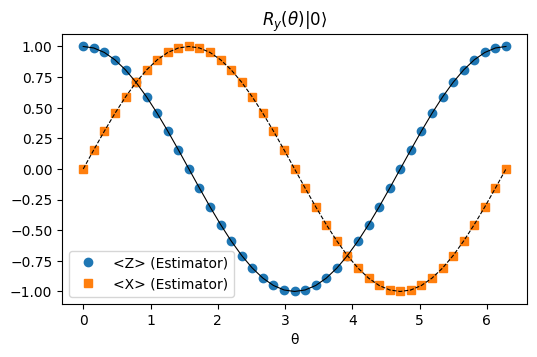

In [24]:
from qiskit.circuit import Parameter, ParameterVector

theta = Parameter("θ")
pqc = QuantumCircuit(1)
pqc.ry(theta, 0)

thetas = np.linspace(0, 2*np.pi, 41)
obs = [[SparsePauliOp("Z")], [SparsePauliOp("X")]]           # shape (2, 1)
params = thetas.reshape(1, -1)                                # shape (1, 41) -> broadcast to (2, 41)
res = estimator.run([(pqc, obs, params)]).result()[0]
print("evs shape:", res.data.evs.shape)

plt.figure(figsize=(6, 3.5))
plt.plot(thetas, res.data.evs[0], "o", label="<Z> (Estimator)")
plt.plot(thetas, res.data.evs[1], "s", label="<X> (Estimator)")
plt.plot(thetas, np.cos(thetas), "k-", lw=0.8); plt.plot(thetas, np.sin(thetas), "k--", lw=0.8)
plt.xlabel("θ"); plt.legend(); plt.title(r"$R_y(\theta)|0\rangle$")
plt.show()

parameters: ParameterView([ParameterVectorElement(p[0]), ParameterVectorElement(p[1]), ParameterVectorElement(p[2]), ParameterVectorElement(p[3])])
bound circuit has 0 free parameters
set 0: {'11': 308, '00': 100, '01': 75, '10': 17}
set 1: {'11': 211, '00': 58, '10': 230, '01': 1}
set 2: {'11': 208, '00': 255, '01': 33, '10': 4}


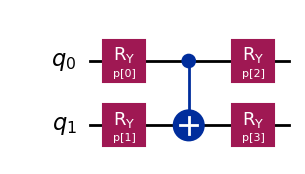

In [25]:
# A 2-qubit parameterized ansatz; bind values with assign_parameters, or pass them to the Sampler
p = ParameterVector("p", 4)
ansatz = QuantumCircuit(2)
ansatz.ry(p[0], 0); ansatz.ry(p[1], 1)
ansatz.cx(0, 1)
ansatz.ry(p[2], 0); ansatz.ry(p[3], 1)
print("parameters:", ansatz.parameters)

bound = ansatz.assign_parameters([0.1, 0.2, 0.3, 0.4])
print("bound circuit has", bound.num_parameters, "free parameters")

ansatz_m = ansatz.measure_all(inplace=False)
values = np.random.default_rng(0).uniform(0, np.pi, size=(3, 4))     # 3 parameter sets
res = sampler.run([(ansatz_m, values)], shots=500).result()[0]
for i in range(3):
    print(f"set {i}:", res.data.meas[i].get_counts())
ansatz.draw("mpl")

## 11. Transpilation: compiling for a device

Quantum hardware has two main constraints:

* It supports only a few native gates, the **basis gates** (for example `rz`, `sx`, `x`, `cx`, or `ecr`/`cz`).
* Two-qubit gates are possible only between physically connected qubits. The connections form the **coupling map**.

The **transpiler** rewrites a circuit into an equivalent circuit that meets these constraints (guide: [*Introduction to transpilation*](https://quantum.cloud.ibm.com/docs/en/guides/transpile)). It works in stages:

`init → layout → routing (insert SWAPs) → translation (to basis gates) → optimization → scheduling`

[`generate_preset_pass_manager`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.transpiler.generate_preset_pass_manager)`(optimization_level, backend=...)` builds a standard pipeline (guide: [*Transpile with pass managers*](https://quantum.cloud.ibm.com/docs/en/guides/transpile-with-pass-managers)). Levels 0–3 trade compile time for circuit quality.

We use [`GenericBackendV2`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.providers.fake_provider.GenericBackendV2), a simulated backend. It has a configurable number of qubits, basis gates and coupling map, and *randomly generated* error rates. It needs no account.

basis gates : ['cx', 'id', 'rz', 'sx', 'x', 'reset', 'delay', 'measure']
coupling map: [(0, 1), (1, 0), (1, 2), (2, 1), (2, 3), (3, 2), (3, 4), (4, 3)]


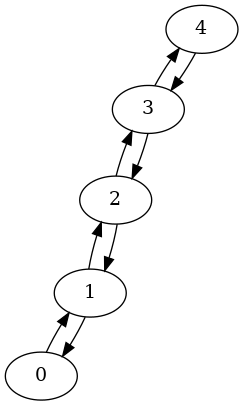

In [26]:
from qiskit.providers.fake_provider import GenericBackendV2
from qiskit.transpiler import generate_preset_pass_manager, CouplingMap

backend = GenericBackendV2(num_qubits=5, coupling_map=CouplingMap.from_line(5), seed=42)
print("basis gates :", backend.operation_names)
print("coupling map:", list(backend.coupling_map.get_edges()))
backend.coupling_map.draw()

In [27]:
# A circuit with all-to-all interactions (not native on a line)
qc = QuantumCircuit(4)
qc.h(0)
qc.cx(0, 3); qc.cx(1, 2); qc.cx(0, 2)
qc.ccx(0, 1, 3)
qc.t(2); qc.s(1)
qc.measure_all()

print(f"{'level':>5} {'depth':>6} {'2q gates':>9}  ops")
compiled = {}
for level in range(4):
    pm = generate_preset_pass_manager(optimization_level=level, backend=backend, seed_transpiler=1)
    tqc = pm.run(qc)
    compiled[level] = tqc
    ops = dict(tqc.count_ops())
    print(f"{level:>5} {tqc.depth():>6} {ops.get('cx', 0):>9}  {ops}")

level  depth  2q gates  ops


    0     32        21  {'cx': 21, 'rz': 15, 'measure': 4, 'sx': 3, 'barrier': 1}
    1     28        18  {'cx': 18, 'rz': 14, 'measure': 4, 'sx': 3, 'barrier': 1}
    2     36        18  {'rz': 24, 'cx': 18, 'sx': 10, 'measure': 4, 'x': 1, 'barrier': 1}
    3     36        18  {'rz': 24, 'cx': 18, 'sx': 10, 'measure': 4, 'x': 1, 'barrier': 1}


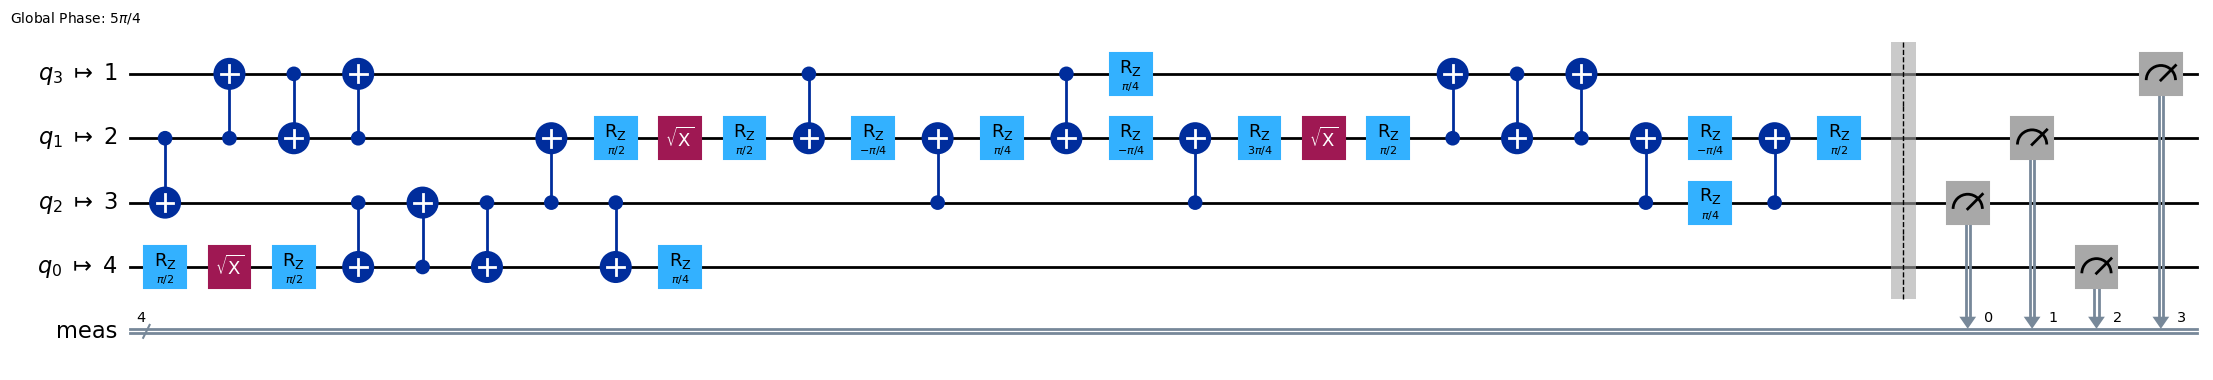

In [28]:
# A higher optimization level does not always give a smaller circuit. Here level 1 gives the smallest depth.
# Draw the level-1 result
compiled[1].draw("mpl", idle_wires=False, fold=40)

In [29]:
# Transpiling to an explicit basis without a backend, e.g. for a different gate set
pm = generate_preset_pass_manager(optimization_level=1, basis_gates=["rz", "sx", "cz"])
h_only = QuantumCircuit(1); h_only.h(0)
print(pm.run(h_only).draw("text"))
print("Equivalent (up to global phase):", Operator(pm.run(h_only)).equiv(Operator(h_only)))

global phase: π/4
   ┌─────────┐┌────┐┌─────────┐
q: ┤ Rz(π/2) ├┤ √X ├┤ Rz(π/2) ├
   └─────────┘└────┘└─────────┘
Equivalent (up to global phase): True


## 12. Noise

Real qubits are not perfect:

* Gates have small errors.
* Qubits **decohere** (lose their quantum state). $T_1$ is the energy relaxation time. $T_2$ is the dephasing time.
* Readout can report 0 as 1, or 1 as 0.

Noisy evolution is described by **density matrices** $\rho$ and **quantum channels**, not by state vectors and unitaries.

`GenericBackendV2` has generated error rates, and `backend.run()` simulates them with Qiskit Aer, if Aer is installed. The noisy histogram has small counts in `01` and `10`. These outcomes are not possible for an ideal Bell state. Deeper circuits collect more error. For this reason, the transpiler tries to reduce depth and the number of two-qubit gates. Error mitigation and error correction are active research areas (see the `qiskit-aer` noise models and the `qiskit-ibm-runtime` error mitigation options).

cx(0, 1) error ≈ 0.0028, duration ≈ 266 ns
qubit 0: T1 ≈ 177 µs, T2 ≈ 144 µs


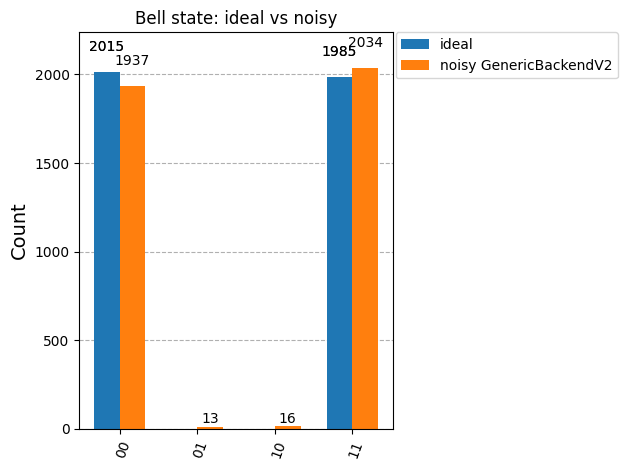

In [30]:
props = backend.target["cx"]
some_edge = next(iter(props))
print(f"cx{some_edge} error ≈ {props[some_edge].error:.4f}, duration ≈ {props[some_edge].duration*1e9:.0f} ns")
print(f"qubit 0: T1 ≈ {backend.qubit_properties(0).t1*1e6:.0f} µs, T2 ≈ {backend.qubit_properties(0).t2*1e6:.0f} µs")

tbell = generate_preset_pass_manager(1, backend=backend, seed_transpiler=0).run(bell_meas)
noisy_counts = backend.run(tbell, shots=4000, seed_simulator=1).result().get_counts()
ideal_counts = StatevectorSampler(seed=1).run([bell_meas], shots=4000).result()[0].data.meas.get_counts()
plot_histogram([ideal_counts, noisy_counts], legend=["ideal", "noisy GenericBackendV2"],
               title="Bell state: ideal vs noisy")

## 13. Quantum teleportation

This section follows the Watrous lesson [*Quantum teleportation*](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation).

**Goal.** Alice holds an unknown qubit $|\psi\rangle = \alpha|0\rangle+\beta|1\rangle$. She sends it to Bob with one shared Bell pair and **two classical bits**. The no-cloning theorem forbids a copy of $|\psi\rangle$. Teleportation *moves* the state.

**Protocol.** Qubit 0 holds $|\psi\rangle$. Qubits 1 and 2 hold the Bell pair. Alice holds qubits 0 and 1. Bob holds qubit 2.

1. Prepare $|\Phi^+\rangle_{12}$.
2. Alice applies CNOT$_{0\to1}$ and then $H_0$. The 3-qubit state becomes
$$
|\psi\rangle_0|\Phi^+\rangle_{12} \;\xrightarrow{\;H_0\,\mathrm{CNOT}_{01}\;}\; \tfrac12\sum_{m_0,m_1\in\{0,1\}} |m_0 m_1\rangle_{01}\otimes X^{m_1}Z^{m_0}|\psi\rangle_2 .
$$
3. Alice measures qubits 0 and 1 and obtains the bits $m_0, m_1$. Each pair has probability ¼, so the outcomes give no information about $\alpha$ and $\beta$.
4. Bob applies $X^{m_1}$ and then $Z^{m_0}$, **conditioned on the classical bits**. His qubit is now $|\psi\rangle$.

Step 4 uses **mid-circuit measurement** and **classical feed-forward**. In Qiskit, we write this with `QuantumCircuit.if_test` (guide: [*Classical feedforward and control flow*](https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow)). This is a dynamic-circuit construct.

> **Note on the installed version.** `StatevectorSampler` cannot run control-flow operations. It raises *"StatevectorSampler cannot handle ControlFlowOp"*. Workaround: we use `SamplerV2` from Qiskit Aer, which has the same V2 PUB interface.

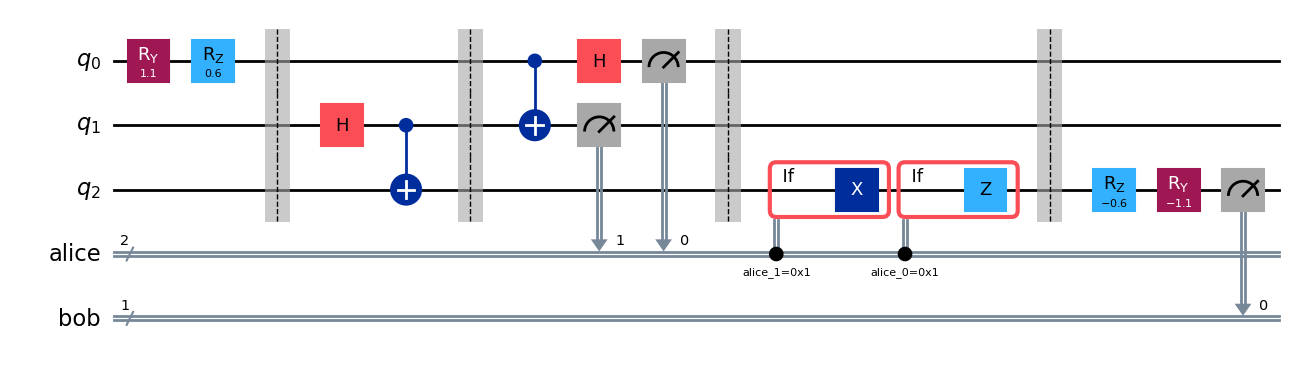

In [31]:
from qiskit_aer.primitives import SamplerV2 as AerSampler

# Unknown state to teleport: Ry(θ)Rz(φ)|0>
th, ph = 1.1, 0.6
prep = QuantumCircuit(1, name="prep")
prep.ry(th, 0); prep.rz(ph, 0)

qr = QuantumRegister(3, "q")
alice = ClassicalRegister(2, "alice")
bob = ClassicalRegister(1, "bob")
tele = QuantumCircuit(qr, alice, bob)

tele.compose(prep, [0], inplace=True)        # |psi> on q0
tele.barrier()
tele.h(1); tele.cx(1, 2)                     # Bell pair on q1, q2
tele.barrier()
tele.cx(0, 1); tele.h(0)                     # Alice's Bell-basis rotation
tele.measure(0, alice[0]); tele.measure(1, alice[1])
tele.barrier()
with tele.if_test((alice[1], 1)):            # classical feed-forward
    tele.x(2)
with tele.if_test((alice[0], 1)):
    tele.z(2)
tele.barrier()
# Verification: undo the preparation on Bob's qubit; if teleportation worked he now has |0>
tele.compose(prep.inverse(), [2], inplace=True)
tele.measure(2, bob[0])
tele.draw("mpl", fold=-1)

Alice's outcomes (uniform, carry no information): {'10': 527, '01': 493, '11': 504, '00': 476}
Bob after un-preparing: {'0': 2000} -> always 0 means |psi> arrived intact


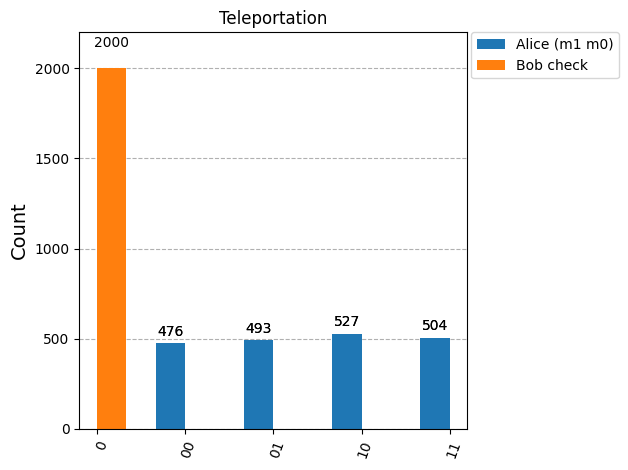

In [32]:
res = AerSampler(seed=11).run([tele], shots=2000).result()[0]
print("Alice's outcomes (uniform, carry no information):", res.data.alice.get_counts())
print("Bob after un-preparing:", res.data.bob.get_counts(), "-> always 0 means |psi> arrived intact")
plot_histogram([res.data.alice.get_counts(), res.data.bob.get_counts()],
               legend=["Alice (m1 m0)", "Bob check"], title="Teleportation")

We can also check teleportation *without* control flow. The **deferred measurement principle** states that a measurement followed by a classically controlled gate is equivalent to a quantum-controlled gate followed by a measurement. We replace the `if_test` blocks with `cx(1,2)` and `cz(0,2)`. The result is a unitary circuit. Bob's reduced state must equal $|\psi\rangle\langle\psi|$.

Fidelity(Bob, |psi>) = 1.0


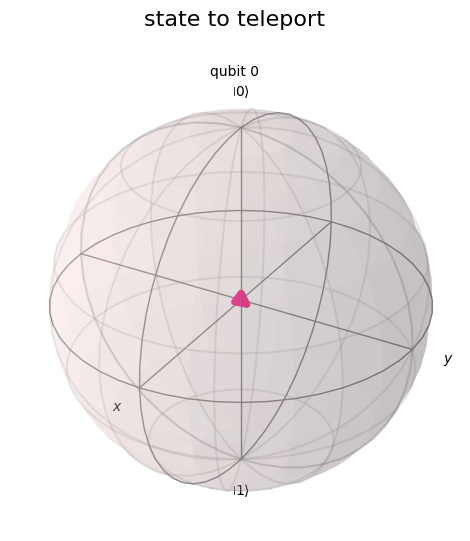

In [33]:
from qiskit.quantum_info import DensityMatrix, state_fidelity
deferred = QuantumCircuit(3)
deferred.compose(prep, [0], inplace=True)
deferred.h(1); deferred.cx(1, 2)
deferred.cx(0, 1); deferred.h(0)
deferred.cx(1, 2); deferred.cz(0, 2)

bob_state = partial_trace(Statevector(deferred), [0, 1])
target = Statevector(prep)
print("Fidelity(Bob, |psi>) =", round(state_fidelity(bob_state, target), 10))
plot_bloch_multivector(target, title="state to teleport")

## 14. Deutsch–Jozsa and Bernstein–Vazirani

These oracle algorithms show how interference reduces the number of queries compared with classical algorithms. An **oracle** is a black-box gate that evaluates a function $f$. This section follows the Watrous lessons [*Quantum query algorithms*](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/introduction) and [*The Deutsch–Jozsa algorithm*](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm). The second page also covers Bernstein–Vazirani.

**Phase kickback.** An oracle acts as $U_f|x\rangle|y\rangle = |x\rangle|y\oplus f(x)\rangle$. If the target qubit is in $|-\rangle$, then $U_f|x\rangle|-\rangle = (-1)^{f(x)}|x\rangle|-\rangle$. The function value appears as a phase on the input register.

**Deutsch–Jozsa.** The promise: $f:\{0,1\}^n\to\{0,1\}$ is either *constant* or *balanced* (0 on exactly half of the inputs). The circuit is $H^{\otimes n}$ → oracle (phase) → $H^{\otimes n}$ → measure. At the end, the amplitude of $|0\cdots0\rangle$ is
$$
\frac{1}{2^n}\sum_x (-1)^{f(x)} = \begin{cases}\pm1 & f\text{ constant}\\ 0 & f\text{ balanced}\end{cases}
$$
Therefore **one** query decides the question. A deterministic classical algorithm needs up to $2^{n-1}+1$ queries.

**Bernstein–Vazirani.** The promise: $f(x) = s\cdot x \bmod 2$ for a hidden bitstring $s$. The same circuit outputs $s$ exactly, with one query. A classical algorithm needs $n$ queries. The oracle is a CNOT from each input qubit $i$ with $s_i=1$ to the target qubit.

constant0 : {'0000': 500} -> CONSTANT
constant1 : {'0000': 500} -> CONSTANT
balanced  : {'0001': 500} -> BALANCED


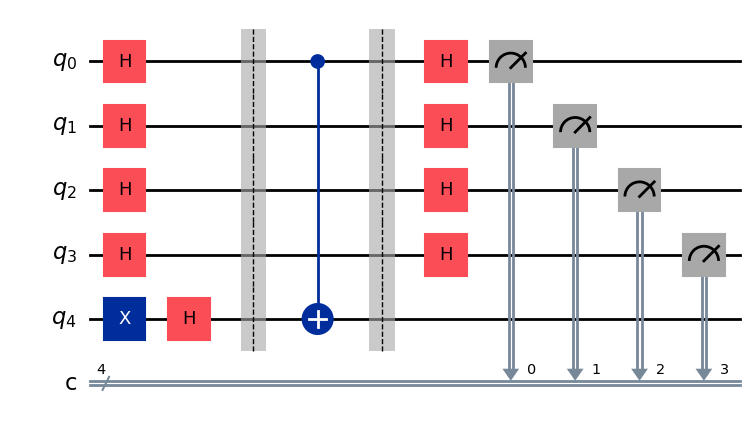

In [34]:
def dj_oracle(n, kind, seed=None):
    # Oracle on n input qubits + 1 target (qubit n). kind in {'constant0','constant1','balanced'}
    o = QuantumCircuit(n + 1, name=f"U_f ({kind})")
    if kind == "constant1":
        o.x(n)
    elif kind == "balanced":
        # f(x) = b·x ⊕ c for a random nonzero b: always balanced
        rng = np.random.default_rng(seed)
        b = rng.integers(0, 2, n)
        if not b.any():
            b[0] = 1
        for i, bit in enumerate(b):
            if bit:
                o.cx(i, n)
        if rng.integers(2):
            o.x(n)
    return o

def query_circuit(n, oracle):
    qc = QuantumCircuit(n + 1, n)
    qc.x(n); qc.h(range(n + 1))           # target in |->, inputs in uniform superposition
    qc.barrier()
    qc.compose(oracle, inplace=True)
    qc.barrier()
    qc.h(range(n))
    qc.measure(range(n), range(n))
    return qc

n = 4
pubs = [query_circuit(n, dj_oracle(n, k, seed=3)) for k in ["constant0", "constant1", "balanced"]]
res = sampler.run(pubs, shots=500).result()
for k, r in zip(["constant0", "constant1", "balanced"], res):
    c = r.data.c.get_counts()
    verdict = "CONSTANT" if c.get("0"*n, 0) == 500 else "BALANCED"
    print(f"{k:10s}: {c} -> {verdict}")
pubs[2].draw("mpl")

secret : 101101
measured: {'101101': 200}


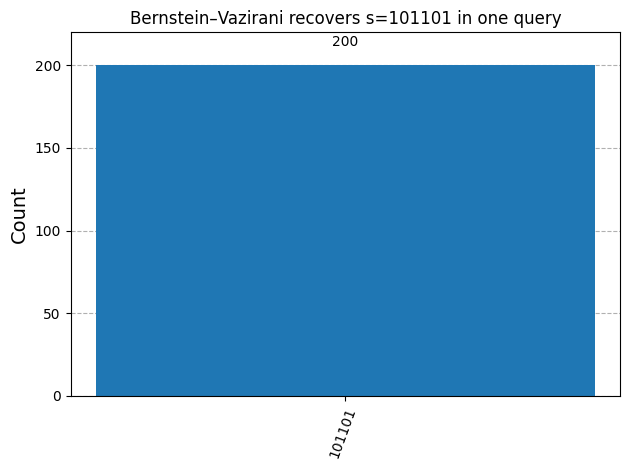

In [35]:
def bv_oracle(s):
    # s given as a bitstring in Qiskit order: s[-1] corresponds to qubit 0
    n = len(s)
    o = QuantumCircuit(n + 1, name=f"s={s}")
    for i, bit in enumerate(reversed(s)):
        if bit == "1":
            o.cx(i, n)
    return o

secret = "101101"
bv = query_circuit(len(secret), bv_oracle(secret))
counts = sampler.run([bv], shots=200).result()[0].data.c.get_counts()
print("secret :", secret)
print("measured:", counts)
plot_histogram(counts, title=f"Bernstein–Vazirani recovers s={secret} in one query")

## 15. Grover search

This section follows the Watrous lesson [*Grover's algorithm*](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/introduction). The Qiskit tutorial [*Grover's algorithm*](https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm) uses the same [`grover_operator`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.grover_operator) function.

**Problem.** There are $N=2^n$ items. An oracle recognizes a marked item $w$. The task is to find $w$. A classical search needs $O(N)$ queries. Grover's algorithm needs $O(\sqrt N)$ queries.

**Components**

* Start in the uniform superposition $|s\rangle = H^{\otimes n}|0\rangle^{\otimes n}$.
* **Oracle** (phase flip): $O_w|x\rangle = (-1)^{[x=w]}|x\rangle$, that is, $O_w = I - 2|w\rangle\langle w|$.
* **Diffuser** (inversion about the mean): $D = 2|s\rangle\langle s| - I$.

**Geometric picture.** Let $|s'\rangle$ be the uniform superposition of the unmarked items. In the plane spanned by $|w\rangle$ and $|s'\rangle$, the state $|s\rangle$ makes a small angle $\theta/2$ with $|s'\rangle$, where $\sin(\theta/2)=1/\sqrt N$. Each Grover iteration $G = D\,O_w$ rotates the state by $\theta$ toward $|w\rangle$. After $k$ iterations:
$$
P(w) = \sin^2\!\big((2k+1)\,\theta/2\big), \qquad k_\text{opt} \approx \frac{\pi}{4}\sqrt N .
$$

For $n=3$ ($N=8$), $k_\text{opt}=2$ gives $P(w)\approx 0.945$. Below, we build the oracle with a multi-controlled Z gate. We also use the Qiskit function `grover_operator`.

Oracle is diag(±1): [ 1.  1.  1.  1.  1. -1.  1.  1.]


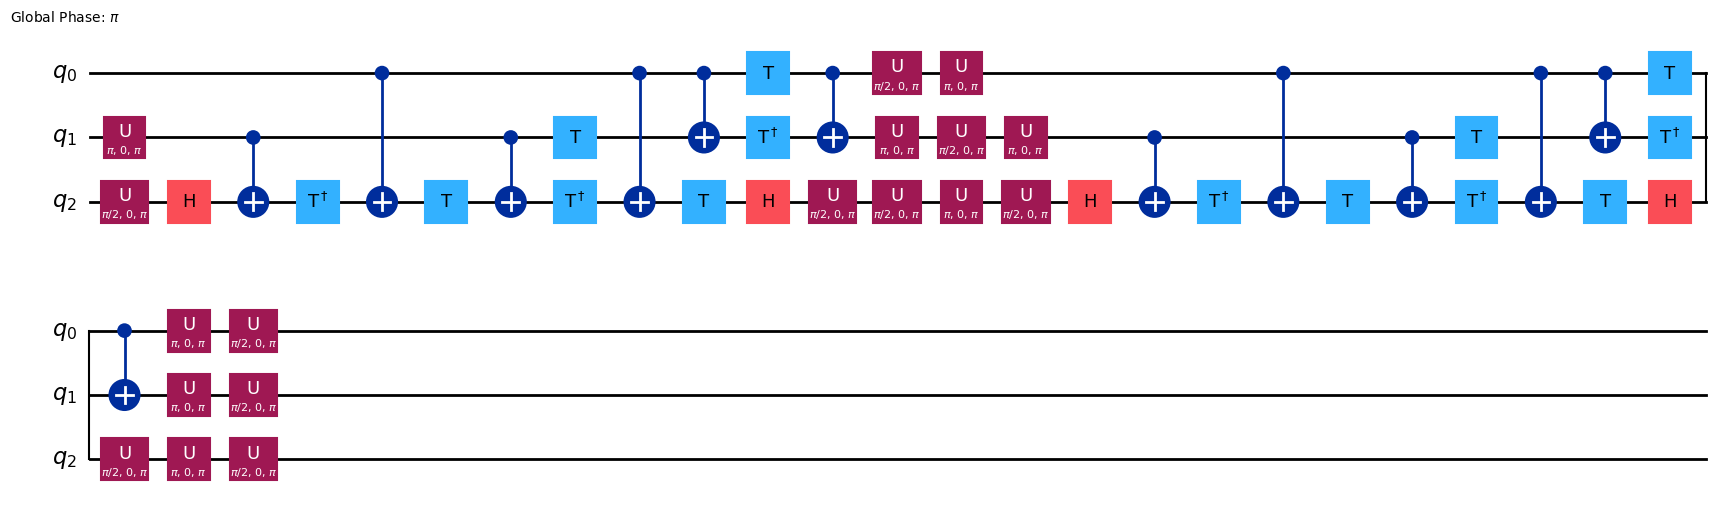

In [36]:
from qiskit.circuit.library import grover_operator, MCXGate

def phase_oracle(marked, n):
    # Flip the phase of each marked bitstring (Qiskit order: rightmost char = qubit 0)
    o = QuantumCircuit(n, name="Oracle")
    for w in marked:
        zeros = [i for i, b in enumerate(reversed(w)) if b == "0"]
        if zeros: o.x(zeros)
        o.h(n - 1); o.append(MCXGate(n - 1), list(range(n))); o.h(n - 1)   # multi-controlled Z
        if zeros: o.x(zeros)
    return o

n, marked = 3, ["101"]
oracle = phase_oracle(marked, n)
print("Oracle is diag(±1):", np.round(np.diag(Operator(oracle).data).real, 3))

G = grover_operator(oracle)             # = diffuser · oracle
G.decompose().draw("mpl")

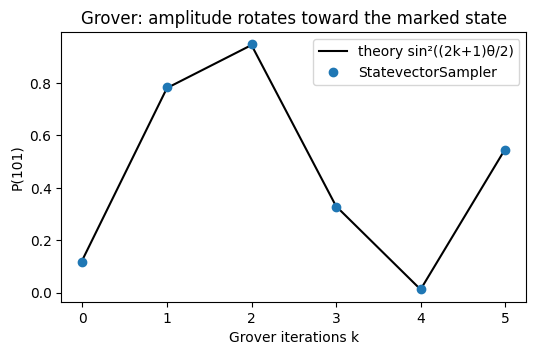

optimal k ≈ π/4·√N = 2.221441469079183


In [37]:
def grover_circuit(oracle, k):
    n = oracle.num_qubits
    qc = QuantumCircuit(n)
    qc.h(range(n))
    for _ in range(k):
        qc.compose(grover_operator(oracle), inplace=True)
    qc.measure_all()
    return qc

N = 2**n
theta = 2*np.arcsin(1/np.sqrt(N))
ks = range(0, 6)
circs = [grover_circuit(oracle, k) for k in ks]
res = sampler.run(circs, shots=2000).result()
p_meas = [r.data.meas.get_counts().get(marked[0], 0)/2000 for r in res]
p_theory = [np.sin((2*k + 1)*theta/2)**2 for k in ks]

plt.figure(figsize=(6, 3.5))
plt.plot(ks, p_theory, "k-", label="theory sin²((2k+1)θ/2)")
plt.plot(ks, p_meas, "o", label="StatevectorSampler")
plt.xlabel("Grover iterations k"); plt.ylabel(f"P({marked[0]})"); plt.legend()
plt.title("Grover: amplitude rotates toward the marked state")
plt.show()
print("optimal k ≈ π/4·√N =", np.pi/4*np.sqrt(N))

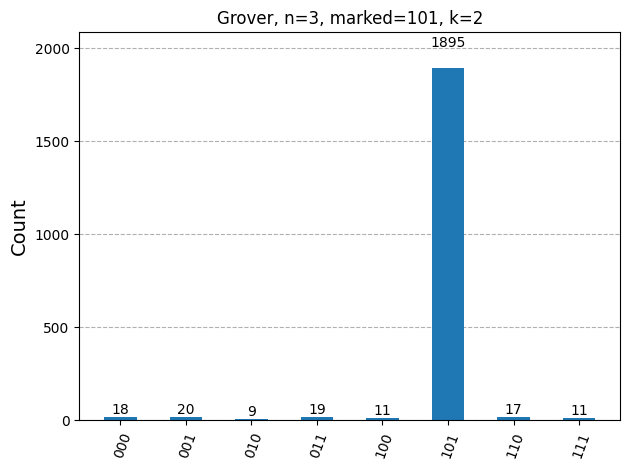

In [38]:
plot_histogram(res[2].data.meas.get_counts(), title="Grover, n=3, marked=101, k=2")

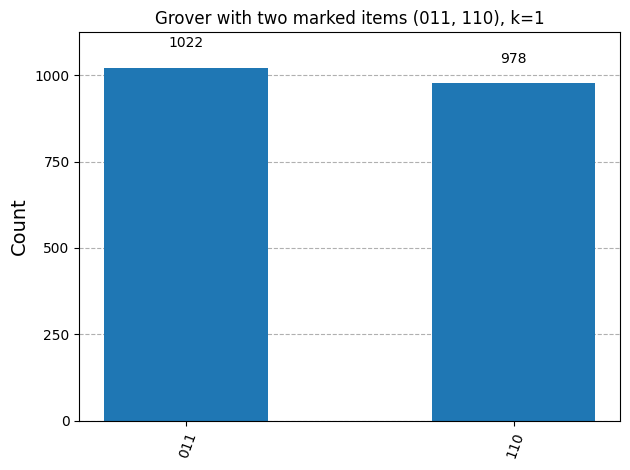

In [39]:
# Two marked items among 8: theta changes (sin²(θ/2) = M/N), and k=1 is already optimal
oracle2 = phase_oracle(["011", "110"], 3)
c2 = sampler.run([grover_circuit(oracle2, 1)], shots=2000).result()[0].data.meas.get_counts()
plot_histogram(c2, title="Grover with two marked items (011, 110), k=1")

## 16. The quantum Fourier transform

The **QFT** is the quantum version of the discrete Fourier transform. It is the main subroutine of phase estimation and of Shor's algorithm. This section follows the Watrous lesson [*The phase estimation procedure*](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/phase-estimation-procedure). On $n$ qubits ($N=2^n$):
$$
\mathrm{QFT}\,|j\rangle = \frac{1}{\sqrt N}\sum_{k=0}^{N-1} e^{2\pi i\,jk/N}\,|k\rangle .
$$
The QFT has a **product form**. Write $j = j_{n-1}\cdots j_0$ in binary. Then
$$
\mathrm{QFT}|j\rangle = \frac{1}{\sqrt N}\bigotimes_{l=1}^{n}\Big(|0\rangle + e^{2\pi i\, j/2^{l}}|1\rangle\Big).
$$
Each output qubit is in an equal superposition, and its *phase* encodes the input. The product form gives a circuit with $O(n^2)$ gates: Hadamards, controlled-phase gates $CP(\pi/2^m)$, and SWAPs at the end that reverse the qubit order. The classical FFT needs $O(N\log N)$ operations, which is exponentially more. However, the output amplitudes of the QFT cannot be read out directly. We compare our circuit with [`QFTGate`](https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.QFTGate).

my QFT == DFT matrix   : True
my QFT == QFTGate       : True


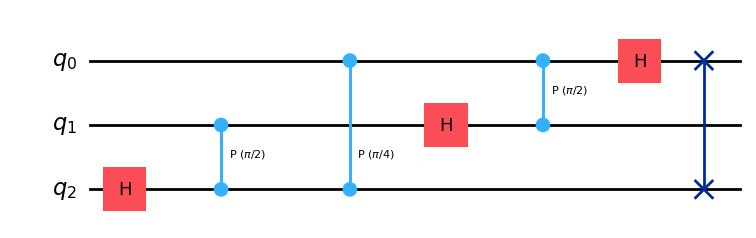

In [40]:
def qft_circuit(n, swaps=True):
    qc = QuantumCircuit(n, name="QFT")
    for j in reversed(range(n)):
        qc.h(j)
        for m, k in enumerate(reversed(range(j)), start=1):
            qc.cp(np.pi / 2**m, k, j)
    if swaps:
        for i in range(n // 2):
            qc.swap(i, n - 1 - i)
    return qc

n = 3
my_qft = qft_circuit(n)

# Compare with the DFT matrix F_{kj} = ω^{jk}/√N, and with Qiskit's QFTGate
N = 2**n
omega = np.exp(2j*np.pi/N)
F = np.array([[omega**(j*k) for j in range(N)] for k in range(N)]) / np.sqrt(N)

from qiskit.circuit.library import QFTGate
lib_qft = QuantumCircuit(n); lib_qft.append(QFTGate(n), range(n))
print("my QFT == DFT matrix   :", np.allclose(Operator(my_qft).data, F))
print("my QFT == QFTGate       :", Operator(my_qft).equiv(Operator(lib_qft)))
my_qft.draw("mpl")

**The phases.** Take the basis state $|5\rangle = |101\rangle$. After the QFT, every qubit is on the equator of its Bloch sphere. A measurement in the $Z$ basis gives uniformly random results. The qubits are rotated by angles proportional to $5/2^l$, so the information is in the phases. The inverse QFT maps the state back to $|101\rangle$ with certainty.

Probabilities after QFT (uniform): [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]


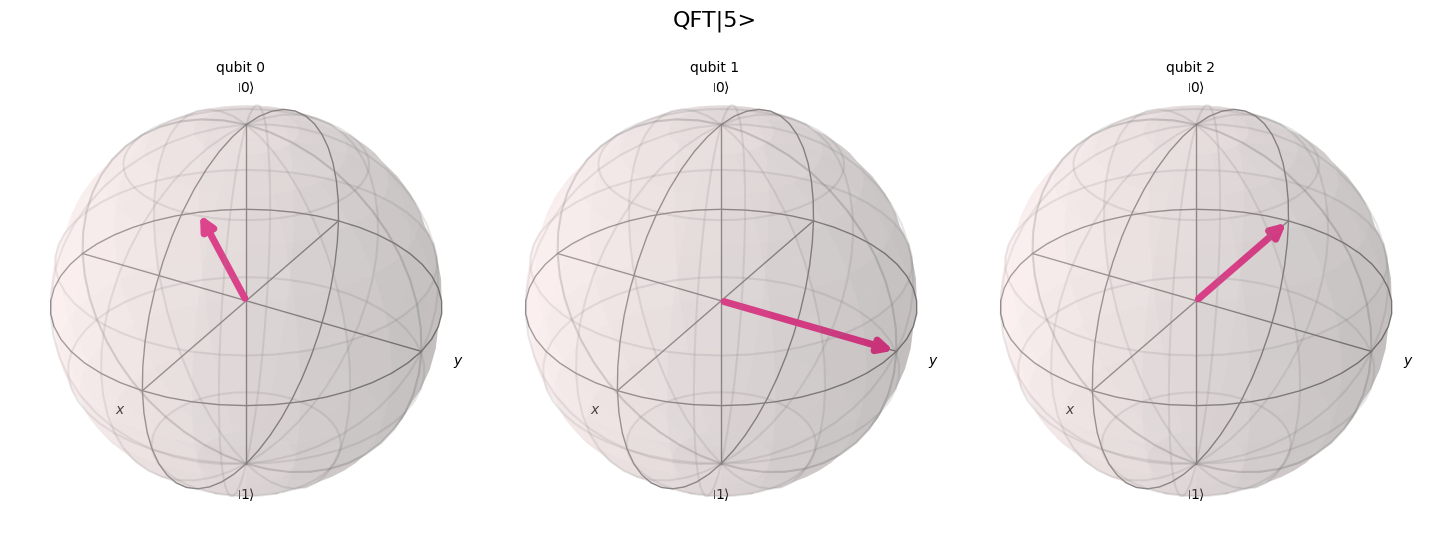

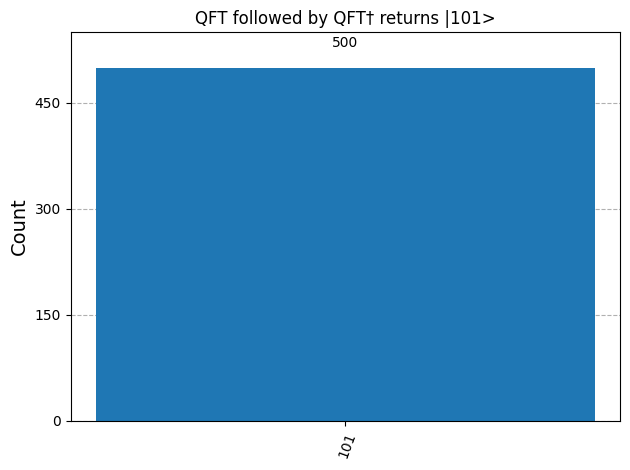

In [41]:
j = 5
prep = QuantumCircuit(n)
for i, b in enumerate(reversed(format(j, f"0{n}b"))):
    if b == "1": prep.x(i)

after_qft = Statevector(prep.compose(my_qft))
print("Probabilities after QFT (uniform):", np.round(after_qft.probabilities(), 3))
display(plot_bloch_multivector(after_qft, title=f"QFT|{j}>"))

roundtrip = prep.compose(my_qft).compose(my_qft.inverse())
roundtrip.measure_all()
plot_histogram(sampler.run([roundtrip], shots=500).result()[0].data.meas.get_counts(),
               title="QFT followed by QFT† returns |101>")

{4: 499, 0: 501} -> only k ∈ {0, 4}: multiples of N/r = 4


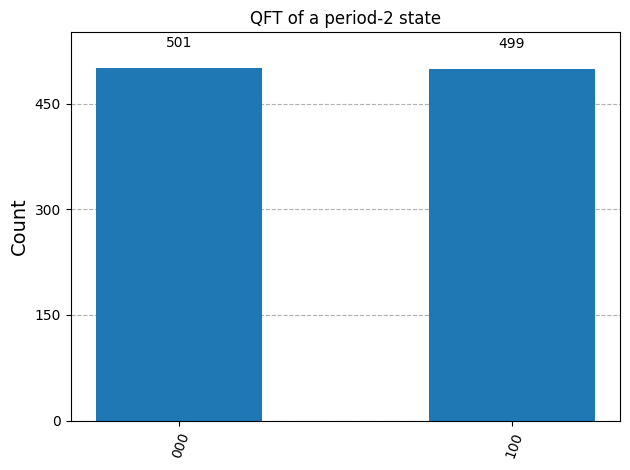

In [42]:
# QFT detects periodicity: a periodic superposition (period r=2 over N=8) maps onto multiples of N/r = 4
n = 3
periodic = QuantumCircuit(n)
periodic.h([1, 2])          # (|0>+|2>+|4>+|6>)/2 : qubit 0 stays 0, period 2
periodic.x(0)               # shift by 1: (|1>+|3>+|5>+|7>)/2, still period 2
periodic.compose(qft_circuit(n), inplace=True)
periodic.measure_all()
c = sampler.run([periodic], shots=1000).result()[0].data.meas.get_counts()
print({int(k, 2): v for k, v in c.items()}, "-> only k ∈ {0, 4}: multiples of N/r = 4")
plot_histogram(c, title="QFT of a period-2 state")

## Summary

* A **qubit** state is a normalized complex vector $\alpha|0\rangle+\beta|1\rangle$. The **Bloch sphere** shows it geometrically. Use `Statevector` and `plot_bloch_multivector`.
* **Measurement** follows the **Born rule** $P(x)=|c_x|^2$ and collapses the state. Probability estimates need many **shots**.
* **Gates** are unitary matrices (rotations of the Bloch sphere). `Operator` gives their matrices. `.equiv` compares them up to a global phase.
* $n$ qubits live in a $2^n$-dimensional **tensor product** space. Qiskit orders qubits **little-endian**: qubit 0 is the rightmost bit.
* **H** and **CNOT** create **entangled** Bell and GHZ states. The reduced density matrix and the entanglement entropy detect entanglement.
* The V2 **primitives** `StatevectorSampler` (bitstrings) and `StatevectorEstimator` (expectation values of `SparsePauliOp` observables) take **PUBs**. PUBs broadcast circuits, observables and parameter values.
* The **transpiler** (`generate_preset_pass_manager`) maps circuits to the basis gates and connectivity of a device. **Noise** reduces the quality of deep circuits.
* Algorithms:
  * **Teleportation**: mid-circuit measurement and `if_test`.
  * **Deutsch–Jozsa and Bernstein–Vazirani**: phase kickback, one query.
  * **Grover**: amplitude amplification with $O(\sqrt N)$ queries.
  * **QFT**: the phases encode the input; the QFT detects periodicity.

The next notebooks in this series cover Qiskit Aer, algorithms and the Qiskit addons.

## References

**Qiskit guides and tutorials**
- Construct circuits: <https://quantum.cloud.ibm.com/docs/en/guides/construct-circuits>
- Visualize circuits: <https://quantum.cloud.ibm.com/docs/en/guides/visualize-circuits>
- Bit ordering in the Qiskit SDK: <https://quantum.cloud.ibm.com/docs/en/guides/bit-ordering>
- Introduction to primitives: <https://quantum.cloud.ibm.com/docs/en/guides/primitives>
- Primitive inputs and outputs: <https://quantum.cloud.ibm.com/docs/en/guides/primitive-input-output>
- Introduction to transpilation: <https://quantum.cloud.ibm.com/docs/en/guides/transpile>
- Transpile with pass managers: <https://quantum.cloud.ibm.com/docs/en/guides/transpile-with-pass-managers>
- Classical feedforward and control flow: <https://quantum.cloud.ibm.com/docs/en/guides/classical-feedforward-and-control-flow>
- Tutorial, Grover's algorithm: <https://quantum.cloud.ibm.com/docs/en/tutorials/grovers-algorithm>

**Qiskit API reference** (<https://quantum.cloud.ibm.com/docs/en/api/qiskit>)
- `Statevector`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Statevector>
- `Operator`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.Operator>
- `SparsePauliOp`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.quantum_info.SparsePauliOp>
- `plot_bloch_multivector`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.visualization.plot_bloch_multivector>
- `QuantumCircuit`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.QuantumCircuit>
- `Parameter`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.Parameter>
- `StatevectorSampler`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorSampler>
- `StatevectorEstimator`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.primitives.StatevectorEstimator>
- `GenericBackendV2`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.providers.fake_provider.GenericBackendV2>
- `generate_preset_pass_manager`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.transpiler.generate_preset_pass_manager>
- `grover_operator`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.grover_operator>
- `QFTGate`: <https://quantum.cloud.ibm.com/docs/en/api/qiskit/qiskit.circuit.library.QFTGate>

**IBM Quantum Learning (J. Watrous)**
- Basics of quantum information: <https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information>
  - Single systems: <https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/introduction>
  - Multiple systems: <https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/introduction>
  - Quantum circuits: <https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/quantum-circuits/introduction>
  - Quantum teleportation: <https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/entanglement-in-action/quantum-teleportation>
- Fundamentals of quantum algorithms: <https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms>
  - Quantum query algorithms: <https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/introduction>
  - The Deutsch–Jozsa algorithm (includes Bernstein–Vazirani): <https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm>
  - Grover's algorithm: <https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/grover-algorithm/introduction>
  - The phase estimation procedure (includes the QFT): <https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/phase-estimation-and-factoring/phase-estimation-procedure>

**Source code**
- Qiskit on GitHub: <https://github.com/Qiskit/qiskit>